# Advanced Medical Data Preprocessing & Predictive Pipeline
**Dataset:** Pima Indians Diabetes Dataset (768 samples, 8 physiological predictors)[cite: 1]  
**Objective:** Construct an end-to-end machine learning pipeline emphasizing clinical-grade data cleaning, MICE imputation, outlier treatment, feature engineering, and model optimization[cite: 1].

In [2]:
# Import required libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)

# Load Pima Indians Diabetes Dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, names=column_names)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Step 1: Handling Invalid Physiological Values & Missingness
In clinical datasets, zero values in certain physiological measurements represent missing data rather than valid zero readings[cite: 1].
* **Identified Missing Fields:** Glucose, BloodPressure, SkinThickness, Insulin, and BMI[cite: 1].
* **Missingness Indicators:** Explicit missingness indicator binary columns are added prior to imputation to preserve informational missingness patterns[cite: 1].
* **Imputation Strategy:** Applied MICE (Multivariate Imputation by Chained Equations) via Scikit-Learn’s `IterativeImputer` to model feature relationships[cite: 1].

In [3]:
cols_with_invalid_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in cols_with_invalid_zeros:
    # Create explicit binary missingness indicator columns
    df[f'{col}_missing'] = df[col].apply(lambda x: 1 if x == 0 else 0)
    # Convert zero values to NaN for imputation
    df[col] = df[col].replace(0, np.nan)

# Apply MICE imputation
imputer = IterativeImputer(max_iter=10, random_state=42)
df[cols_with_invalid_zeros] = imputer.fit_transform(df[cols_with_invalid_zeros])

print("Missing values after MICE imputation:", df[cols_with_invalid_zeros].isnull().sum().sum())

Missing values after MICE imputation: 0


### Step 2: Domain-Informed Feature Engineering
To capture complex non-linear clinical interactions, two features were engineered[cite: 1]:
1. **Glucose-BMI Interaction Term (`Glucose_BMI_Interaction`):** Captures the combined synergistic effect of high systemic glucose and high body mass index[cite: 1].
2. **Age Risk Stratification (`Age_Risk_Group`):** Bins continuous age into discrete clinical risk tiers[cite: 1].

In [4]:
# Glucose-BMI Interaction Term
df['Glucose_BMI_Interaction'] = df['Glucose'] * df['BMI']

# Age Risk Stratification
bins = [0, 30, 45, 60, 100]
labels = [0, 1, 2, 3] # Ascending risk brackets
df['Age_Risk_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, include_lowest=True).astype(int)

print(df[['Glucose_BMI_Interaction', 'Age_Risk_Group']].head())

   Glucose_BMI_Interaction  Age_Risk_Group
0                   4972.8               2
1                   2261.0               1
2                   4263.9               1
3                   2500.9               0
4                   5904.7               1


### Step 3: Outlier Handling & Feature Scaling
* **Outlier Mitigation:** Applied percentile-based Winsorization (1st and 99th percentiles) to cap severe continuous outliers while preserving total sample count[cite: 1].
* **Feature Normalization:** Applied `QuantileTransformer` to map features to a normal distribution, mitigating skewness in variables like Insulin and DiabetesPedigreeFunction[cite: 1].

In [6]:
# Percentile-based Winsorization
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction']:
    lower_bound = df[col].quantile(0.01)
    upper_bound = df[col].quantile(0.99)
    df[col] = np.clip(df[col], lower_bound, upper_bound)

# Separate features and target
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Feature Normalization using QuantileTransformer
numerical_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Glucose_BMI_Interaction']
scaler = QuantileTransformer(output_distribution='normal', random_state=42)
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

### Step 4: Model Architecture & Data Splitting
* **Data Splitting:** Stratified Train-Test split (80/20 ratio) to maintain class ratio integrity[cite: 1].
* **Classifier Choice:** XGBoost classifier configured to handle structured tabular classification tasks effectively.

In [7]:
# Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

# Base XGBoost Classifier
xgb_clf = xgb.XGBClassifier(eval_metric='logloss', random_state=42)

### Step 5: Hyperparameter Tuning via GridSearchCV
Optimizing hyperparameters using Stratified 5-Fold Cross-Validation evaluated primarily via Area Under the ROC Curve (AU-ROC) to ensure robust generalization on minority clinical outcomes[cite: 1].

In [8]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Best Hyperparameters Found: {grid_search.best_params_}")

Best Hyperparameters Found: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}


### Step 6: Model Evaluation & Performance Metrics
Evaluating model performance using clinical metrics including Accuracy, Precision, Recall, F1-Score, AU-ROC, and AU-PRC[cite: 1].

In [9]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- CLINICAL MODEL PERFORMANCE METRICS ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"AU-ROC:    {roc_auc_score(y_test, y_proba):.4f}")
print(f"AU-PRC:    {average_precision_score(y_test, y_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

--- CLINICAL MODEL PERFORMANCE METRICS ---
Accuracy:  0.7338
Precision: 0.6383
Recall:    0.5556
F1-Score:  0.5941
AU-ROC:    0.8202
AU-PRC:    0.6923

Confusion Matrix:
[[83 17]
 [24 30]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       100
           1       0.64      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.70       154
weighted avg       0.73      0.73      0.73       154



### Step 7: Model Performance Visualizations
To thoroughly evaluate the classification model, we visualize:
1. **Confusion Matrix Heatmap:** To analyze true positives, true negatives, false positives, and false negatives.
2. **ROC & Precision-Recall Curves:** To assess diagnostic trade-offs across classification thresholds.

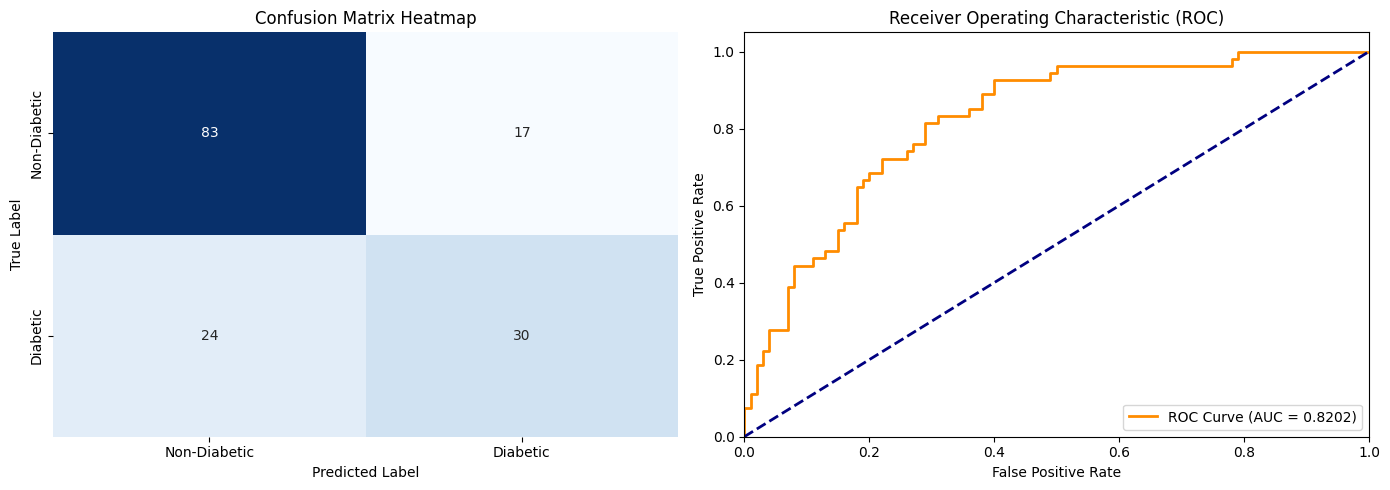

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
axes[0].set_title('Confusion Matrix Heatmap')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Step 8: Model Interpretability via SHAP (SHapley Additive exPlanations)
To ensure transparency in clinical prediction, model explainability is implemented:
* **Global Interpretability:** SHAP summary bar plots rank features by global importance[cite: 1].
* **Directional Impact:** SHAP beeswarm plots visualize how high vs. low feature values drive predictions toward positive diagnoses[cite: 1].

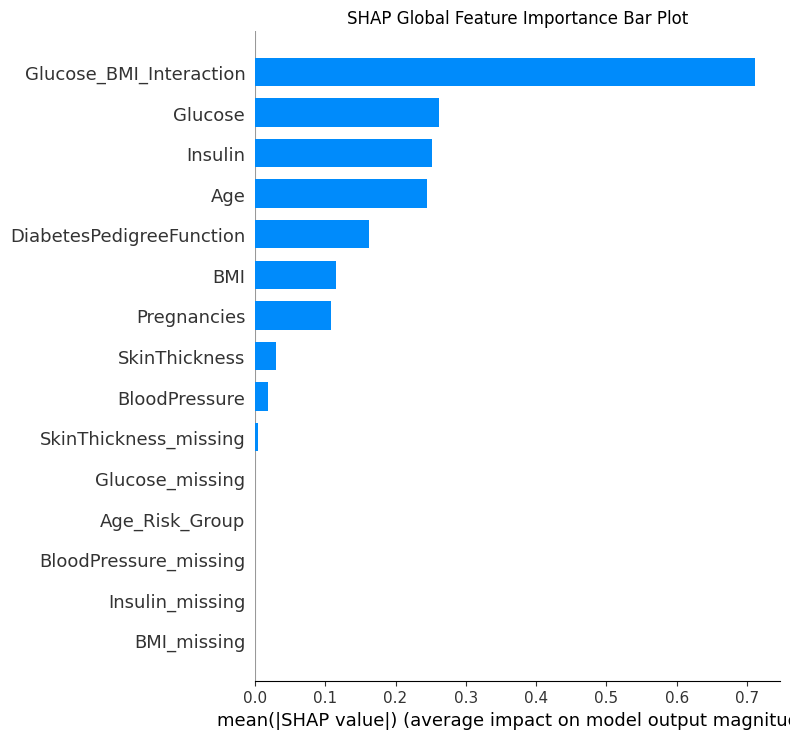

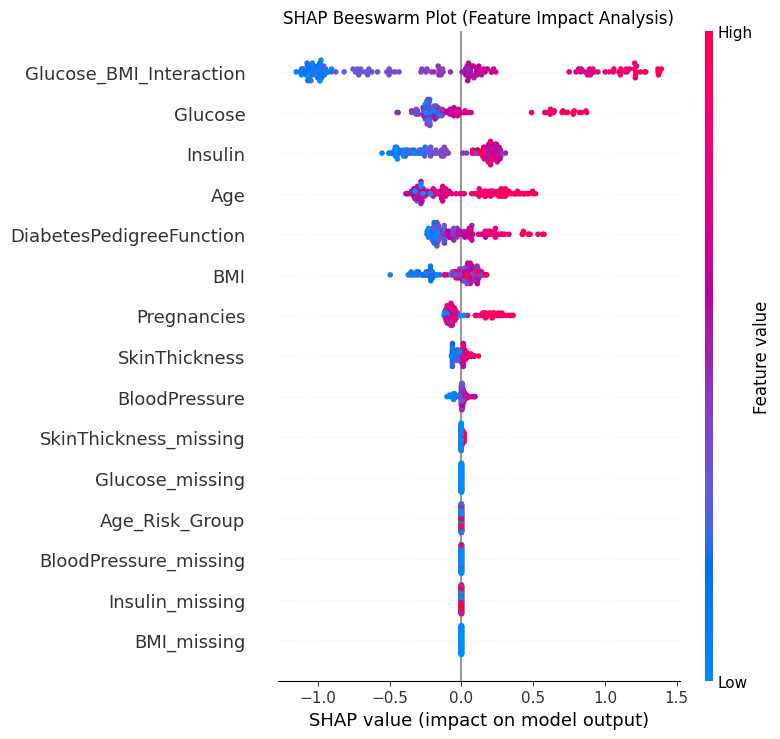

In [11]:
import shap

# Initialize SHAP Explainer using the trained XGBoost model
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

# 1. SHAP Summary Bar Plot (Global Importance)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance Bar Plot")
plt.tight_layout()
plt.show()

# 2. SHAP Beeswarm Plot (Directional Impact)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Beeswarm Plot (Feature Impact Analysis)")
plt.tight_layout()
plt.show()